# GLM testing

## Simulation

In [120]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

In [2]:
n_bins = 20

# assume the "true" model is:
# log(rate) = beta0 + beta_a * a + beta_b * b
beta0 = 1.0
beta_a = 0.1
beta_b = 0.2

a_values = np.linspace(0, 1, n_bins)
b_values = np.linspace(0, 1, n_bins)

A, B = np.meshgrid(a_values, b_values, indexing='ij')

rate = np.exp(beta0 + beta_a * A + beta_b * B)

# Simulate spike counts (firing rate map) using the Poisson distribution
np.random.seed(0)  # for reproducibility
firing_rate_map = np.random.poisson(rate)

# -----------------------------
# 1. Global GLM: Use all data at once
# -----------------------------
# Flatten the firing rate map and corresponding a, b values
y_global = firing_rate_map.flatten()  # response variable (spike counts)
a_global = A.flatten()
b_global = B.flatten()

# Build the design matrix with an intercept, a, and b.
X_global = np.column_stack([np.ones_like(a_global), a_global, b_global])

# Fit the GLM using a Poisson family
model_global = sm.GLM(y_global, X_global, family=sm.families.Poisson())
results_global = model_global.fit()

print("Global GLM coefficients:")
print("Intercept: {:.3f}, beta_a: {:.3f}, beta_b: {:.3f}".format(*results_global.params))

# -----------------------------
# 2. Conditional GLM: Fit GLM for each fixed a (i.e., each row) to estimate the effect of b alone
# -----------------------------
beta_b_slices = []  # will store the beta_b from each conditional fit

# Loop over each row (each fixed a value)
for i in range(n_bins):
    # Extract the firing rate vector for this fixed a (across all b bins)
    y_slice = firing_rate_map[i, :]  # shape: (n_bins,)
    
    # Use the corresponding b values (same for every row in this example)
    b_slice = b_values  # shape: (n_bins,)
    
    # Build design matrix: intercept and b
    X_slice = np.column_stack([np.ones_like(b_slice), b_slice])
    
    # Fit the GLM for this slice
    model_slice = sm.GLM(y_slice, X_slice, family=sm.families.Poisson())
    result_slice = model_slice.fit()
    
    # Append the coefficient for b (index 1 in the parameters)
    beta_b_slices.append(result_slice.params[1])

beta_b_slices = np.array(beta_b_slices)
print("\nConditional GLM beta_b values for each fixed a:")
print(beta_b_slices)

# To summarize the influence of b across all slices, average the coefficients.
beta_b_average = np.mean(beta_b_slices)
print("\nAverage beta_b from conditional GLMs: {:.3f}".format(beta_b_average))


Global GLM coefficients:
Intercept: 0.948, beta_a: 0.194, beta_b: 0.213

Conditional GLM beta_b values for each fixed a:
[-0.6958134   0.8402762   0.14820838 -0.18444787  0.51855478  0.98690537
  0.07519584  0.16507315  0.01823719 -0.09525409  0.6140524  -0.20423919
 -0.40485132  0.93996484  0.54454404  0.58278247  0.57069967  0.73536923
 -0.39495834 -0.46763582]

Average beta_b from conditional GLMs: 0.215


Ground-truth parameters
Intercept: 2.000, beta_b: 0.000, covariance: 0.990
Global GLM coefficients:
Intercept: 2.092, beta_a: 0.953, beta_b: -0.267

Conditional GLM beta_b values for each a bin:
[-34.97700735          nan  -1.83469478  -4.9265408    1.29051124
   2.15324505  -4.20528597  -0.65981704   0.4338425    1.44075876
  -1.52771057  -1.05303965   4.48906813   2.89027196  -2.64906356
  -3.27943882   3.91229791  -2.54717159          nan  -4.19815378]

Conditional GLM # samples for each a bin:
[2, 1, 8, 10, 9, 9, 21, 22, 35, 25, 31, 29, 26, 20, 19, 13, 8, 8, 0, 3]

Average beta_b from conditional GLMs: -2.514


/home/mag/miniconda3/envs/predictive-code/lib/python3.11/site-packages/statsmodels/regression/_tools.py:121: RuntimeWarning: divide by zero encountered in scalar divide
  scale = np.dot(wresid, wresid) / df_resid


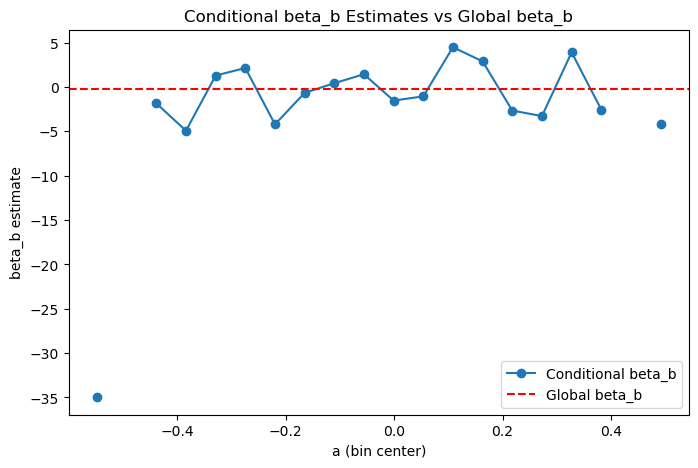

In [425]:
n_samples = 300   
rho = 0.99                # correlation coefficient between a and b
beta0 = 2.0               # intercept
beta_b = 0.0              # true effect of stimulus b

mu = 0.7 # tuning for a
sigma=0.2
amplitude = 2

print("Ground-truth parameters")
print("Intercept: {:.3f}, beta_b: {:.3f}, covariance: {:.3f}".format(beta0, beta_b, rho))

mean = [0, 0]
variance_a = 0.05  # Variance for a
variance_b = 0.05  # Variance for b
cov_ab = rho * np.sqrt(variance_a * variance_b)
cov = [[variance_a, cov_ab],
       [cov_ab, variance_b]]
stimuli = np.random.multivariate_normal(mean, cov, size=n_samples)
a_samples = stimuli[:, 0]
b_samples = stimuli[:, 1]

def tuning_a(a, mu, sigma, amplitude):
    return amplitude * np.exp(- (a - mu)**2 / (2 * sigma**2))

def tuning_b(b, beta_b):
    return beta_b # * b

rates = np.exp(beta0 + tuning_a(a_samples, mu, sigma, amplitude) + tuning_b(b_samples, beta_b))
spike_counts = np.random.poisson(rates)

# -----------------------------
# Global GLM
# -----------------------------
X_global = np.column_stack([np.ones(n_samples), a_samples, b_samples])
model_global = sm.GLM(spike_counts, X_global, family=sm.families.Poisson())
results_global = model_global.fit()
print("Global GLM coefficients:")
print("Intercept: {:.3f}, beta_a: {:.3f}, beta_b: {:.3f}".format(*results_global.params))

# -----------------------------
# Conditional GLM
# -----------------------------
n_bins = 20
bin_edges = np.linspace(np.min(a_samples), np.max(a_samples), n_bins+1)
bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])
conditional_beta_b = []

counts = []
for i in range(n_bins):
    indices = (a_samples >= bin_edges[i]) & (a_samples < bin_edges[i+1])
    counts.append(np.sum(indices))
    
    if np.sum(indices) < 2:
        conditional_beta_b.append(np.nan)
        continue
    
    y_bin = spike_counts[indices]
    b_bin = b_samples[indices]
    
    X_bin = np.column_stack([np.ones(len(b_bin)), b_bin])
    model_bin = sm.GLM(y_bin, X_bin, family=sm.families.Poisson())
    result_bin = model_bin.fit()
    
    conditional_beta_b.append(result_bin.params[1])

conditional_beta_b = np.array(conditional_beta_b)
valid = ~np.isnan(conditional_beta_b)
average_beta_b = np.mean(conditional_beta_b[valid])

print("\nConditional GLM beta_b values for each a bin:")
print(conditional_beta_b)
print("\nConditional GLM # samples for each a bin:")
print(counts)
print("\nAverage beta_b from conditional GLMs: {:.3f}".format(average_beta_b))

plt.figure(figsize=(8, 5))
plt.plot(bin_centers, conditional_beta_b, 'o-', label='Conditional beta_b')
plt.axhline(y=results_global.params[2], color='r', linestyle='--', label='Global beta_b')
plt.xlabel('a (bin center)')
plt.ylabel('beta_b estimate')
plt.legend()
plt.title('Conditional beta_b Estimates vs Global beta_b')
plt.show()


In [415]:
import numpy as np
import statsmodels.api as sm
from tqdm import tqdm

# Number of simulation iterations
n_simulations = 500

# Containers for our estimates
global_beta_bs = []
global_beta_as = []
conditional_avg_beta_bs = []

for sim in tqdm(range(n_simulations)):
    try:
        # -----------------------------
        # Simulation parameters
        # -----------------------------
        n_samples = 300   
        rho = 0.99                # correlation coefficient between a and b
        beta0 = 1.0               # intercept
        beta_b = 0.3              # true effect of stimulus b
    
        mu = 1.0  # tuning for a
        sigma = 0.4
        amplitude = 5
    
        mean = [0, 0]
        variance_a = 1.0 
        variance_b = 1.0 
        cov_ab = rho * np.sqrt(variance_a * variance_b)
        cov = [[variance_a, cov_ab],
               [cov_ab, variance_b]]
        stimuli = np.random.multivariate_normal(mean, cov, size=n_samples)
        a_samples = stimuli[:, 0]
        b_samples = stimuli[:, 1]
    
        # Tuning functions
        def tuning_a(a, mu, sigma, amplitude):
            return amplitude * np.exp(- (a - mu)**2 / (2 * sigma**2))
        
        def tuning_b(b, beta_b):
            return beta_b #* b
    
        # Generate spike counts
        rates = np.exp(beta0 + tuning_a(a_samples, mu, sigma, amplitude) + tuning_b(b_samples, beta_b))
        spike_counts = np.random.poisson(rates)

        X_global = np.column_stack([np.ones(n_samples), a_samples, b_samples])
        model_global = sm.GLM(spike_counts, X_global, family=sm.families.Poisson())
        results_global = model_global.fit()
        # In the printed output below, the order is: intercept, beta_a, beta_b.
        # So the beta_b is at index 2:
        global_beta_a = results_global.params[1]
        global_beta_as.append(global_beta_a)
        global_beta_b = results_global.params[2]
        global_beta_bs.append(global_beta_b)

    except:
        continue

# Convert lists to numpy arrays for analysis
global_beta_bs = np.array(global_beta_bs)
global_beta_as = np.array(global_beta_as)
#conditional_avg_beta_bs = np.array(conditional_avg_beta_bs)

# Compute the overall mean and variance for each estimate
global_mean = np.mean(global_beta_bs)
global_variance = np.var(global_beta_bs)
global_mean_a = np.mean(global_beta_as)
global_variance_a = np.var(global_beta_as)

#conditional_mean = np.mean(conditional_avg_beta_bs)
#conditional_variance = np.var(conditional_avg_beta_bs)

print("Ground-truth parameters")
print("Intercept: {:.3f}, beta_b: {:.3f}, covariance: {:.3f}".format(beta0, beta_b, rho))

print("Global GLM beta_b estimates: mean = {:.3f}, variance = {:.3f}".format(global_mean, global_variance))
print("Global GLM beta_a estimates: mean = {:.3f}, variance = {:.3f}".format(global_mean_a, global_variance_a))
#print("Conditional GLM average beta_b estimates: mean = {:.3f}, variance = {:.3f}".format(conditional_mean, conditional_variance))


100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 500/500 [00:01<00:00, 473.33it/s]

Ground-truth parameters
Intercept: 1.000, beta_b: 0.300, covariance: 0.990
Global GLM beta_b estimates: mean = 0.681, variance = 0.127
Global GLM beta_a estimates: mean = -0.269, variance = 0.121


Optimization terminated successfully.
         Current function value: 1121.477462
         Iterations: 15
         Function evaluations: 16
         Gradient evaluations: 16
         Hessian evaluations: 15


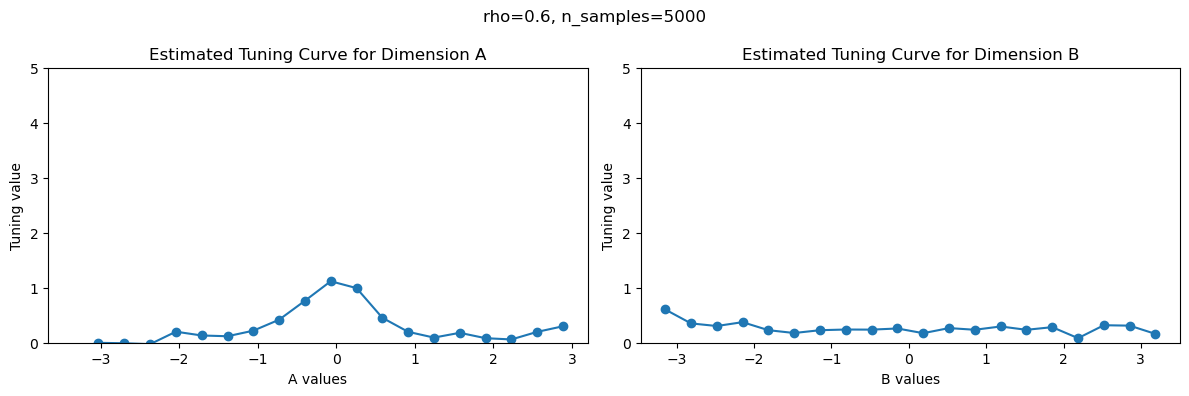

In [121]:
import numpy as np
from scipy.optimize import minimize
from scipy.sparse import diags
from scipy.linalg import block_diag
from scipy.special import gammaln

# ------------------------------
# Data Generation (as provided)
# ------------------------------
n_samples = 5000   
rho = 0.6                # correlation coefficient between a and b
beta0 = 0.3               # intercept
beta_b = 0.1              # true effect of stimulus b
    
mu = 0.0  # tuning for a
sigma = 0.4
amplitude = 1
    
mean = [0, 0]
variance_a = 1.0 
variance_b = 1.0 
cov_ab = rho * np.sqrt(variance_a * variance_b)
cov = [[variance_a, cov_ab],
        [cov_ab, variance_b]]
stimuli = np.random.multivariate_normal(mean, cov, size=n_samples)
a_samples = stimuli[:, 0]
b_samples = stimuli[:, 1]

def tuning_a(a, mu, sigma, amplitude):
    return amplitude * np.exp(- (a - mu)**2 / (2 * sigma**2))
        
def tuning_b(b, beta_b):
    return beta_b  

rates = np.exp(beta0 + tuning_a(a_samples, mu, sigma, amplitude) + tuning_b(b_samples, beta_b))
spike_counts = np.random.poisson(rates)

# ---------------------------------------------
# Create a design matrix by binning the stimuli
# ---------------------------------------------
def create_design_matrix(a_samples, b_samples, nbins_a, nbins_b):
    """
    Bins a_samples and b_samples into nbins_a and nbins_b bins,
    then creates a one-hot encoding for each. The design matrix X is the
    concatenation of the two one-hot matrices.
    """
    a_edges = np.linspace(np.min(a_samples), np.max(a_samples), nbins_a + 1)
    b_edges = np.linspace(np.min(b_samples), np.max(b_samples), nbins_b + 1)
    
    a_bin = np.digitize(a_samples, a_edges) - 1
    b_bin = np.digitize(b_samples, b_edges) - 1

    a_bin = np.clip(a_bin, 0, nbins_a - 1)
    b_bin = np.clip(b_bin, 0, nbins_b - 1)
    
    N = len(a_samples)
    X_a = np.zeros((N, nbins_a))
    X_b = np.zeros((N, nbins_b))
    X_a[np.arange(N), a_bin] = 1
    X_b[np.arange(N), b_bin] = 1
    
    X = np.hstack([X_a, X_b])
    return X

def rough_penalty_1d(param, beta):
    """
    Computes a 1D roughness penalty for a tuning curve.
    Returns the penalty cost J, its gradient J_g, and Hessian J_h.
    """
    n = param.size
    if n <= 1:
        return 0.0, np.zeros_like(param), np.zeros((n, n))
    # Difference operator: each row computes diff between adjacent bins
    D1 = diags([-np.ones(n - 1), np.ones(n - 1)], [0, 1], shape=(n - 1, n)).toarray()
    DD1 = D1.T @ D1
    J = beta * 0.5 * param.T.dot(DD1.dot(param))
    J_g = beta * (DD1.dot(param))
    J_h = beta * DD1
    return J, J_g, J_h

def ln_poisson_model(param, X, Y, L1, L2, beta_penalty):
    """
    Computes the (negative) log-likelihood, gradient, and Hessian for
    a Poisson model whose log-rate is given by a tuning curve for dimension a (length L1)
    and a tuning curve for dimension b (length L2). Both tuning curves are penalized using
    a 1D roughness penalty with weight beta_penalty.
    
    Parameters:
      param      : concatenated tuning curves [f_a, f_b] (length L1+L2)
      X          : design matrix (N x (L1+L2)), e.g. one-hot encoding of bins.
      Y          : observed spike counts (N,)
      L1         : number of bins (parameters) for dimension a.
      L2         : number of bins (parameters) for dimension b.
      beta_penalty: regularization weight.
      
    Returns:
      f          : scalar cost value.
      grad       : gradient vector.
      H          : Hessian matrix.
    """
    u = X.dot(param)
    rate = np.exp(u)
    
    # Negative log-likelihood (ignoring constant terms)
    f_glm = np.sum(rate - Y * u)
    grad_glm = X.T.dot(rate - Y)
    H_glm = X.T.dot((rate[:, None] * X))
    
    # Split parameter vector into tuning curves for a and b.
    f_a, grad_a, H_a = rough_penalty_1d(param[:L1], beta_penalty)
    f_b, grad_b, H_b = rough_penalty_1d(param[L1:], beta_penalty)
    
    f_total = f_glm + f_a + f_b
    grad_total = np.concatenate([grad_glm[:L1] + grad_a, grad_glm[L1:] + grad_b])
    H_total = H_glm + block_diag(H_a, H_b)
    
    return f_total, grad_total, H_total

def fit_poisson_model(a_samples, b_samples, spike_counts, nbins_a=20, nbins_b=20, beta_penalty=10.0):
    """
    Bins the stimulus dimensions, creates the design matrix, and fits
    the Poisson model using our simplified ln_poisson_model.
    """
    X = create_design_matrix(a_samples, b_samples, nbins_a, nbins_b)
    L1 = nbins_a
    L2 = nbins_b
    init_param = np.zeros(L1 + L2)  # initial guess: flat tuning curves
    
    def objective_with_hess(p):
        f, grad, hess = ln_poisson_model(p, X, spike_counts, L1, L2, beta_penalty)
        return f, grad, hess

    res = minimize(fun=lambda p: objective_with_hess(p)[0],
                   x0=init_param,
                   jac=lambda p: objective_with_hess(p)[1],
                   hess=lambda p: objective_with_hess(p)[2],
                   method='trust-ncg',
                   options={'disp': True})
    return res.x, X

fitted_params, X_design = fit_poisson_model(a_samples, b_samples, spike_counts,
                                            nbins_a=20, nbins_b=20, beta_penalty=10.0)
#print("Fitted parameters:", fitted_params)


import matplotlib.pyplot as plt

# Assume these values were used when fitting the model:
nbins_a = 20
nbins_b = 20

# Compute bin edges and centers for dimension a
a_edges = np.linspace(np.min(a_samples), np.max(a_samples), nbins_a + 1)
a_centers = (a_edges[:-1] + a_edges[1:]) / 2

# Compute bin edges and centers for dimension b
b_edges = np.linspace(np.min(b_samples), np.max(b_samples), nbins_b + 1)
b_centers = (b_edges[:-1] + b_edges[1:]) / 2

# Split the fitted parameters into the two tuning curves
tuning_a_est = fitted_params[:nbins_a]
tuning_b_est = fitted_params[nbins_a:]

# Plot the tuning curves
fig, axs = plt.subplots(1, 2, figsize=(12, 4))

fig.suptitle(f'rho={rho}, n_samples={n_samples}')
# Plot tuning curve for dimension a
axs[0].plot(a_centers, tuning_a_est, marker='o', linestyle='-')
axs[0].set_title('Estimated Tuning Curve for Dimension A')
axs[0].set_xlabel('A values')
axs[0].set_ylabel('Tuning value')
axs[0].set_ylim(0, 5)

# Plot tuning curve for dimension b
axs[1].plot(b_centers, tuning_b_est, marker='o', linestyle='-')
axs[1].set_title('Estimated Tuning Curve for Dimension B')
axs[1].set_xlabel('B values')
axs[1].set_ylabel('Tuning value')
axs[1].set_ylim(0, 5)

plt.tight_layout()
plt.show()


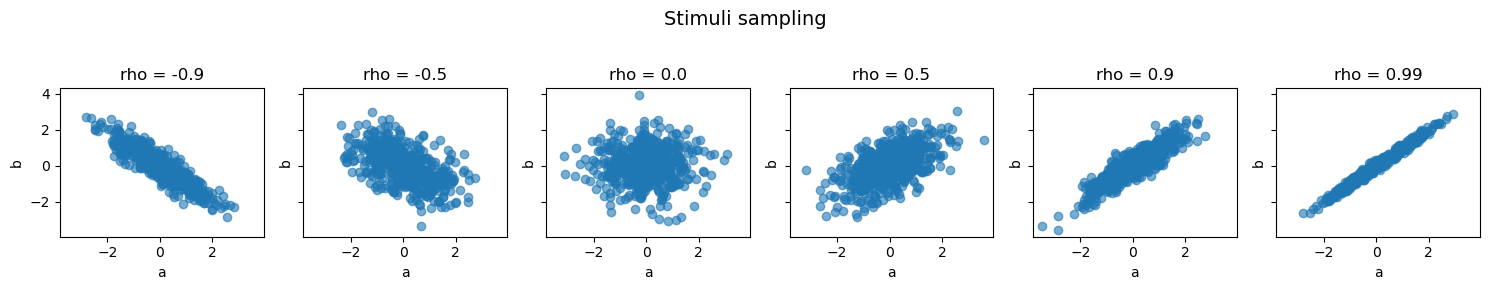

In [129]:

rhos = [-0.9, -0.5, 0.0, 0.5, 0.9, 0.99]
n_samples = 500 

# Create subplots
fig, axes = plt.subplots(1, len(rhos), figsize=(15, 3), sharex=True, sharey=True)

for ax, rho in zip(axes, rhos):
    mean = [0, 0]
    cov = [[1, rho], [rho, 1]] 
    samples = np.random.multivariate_normal(mean, cov, n_samples)
    a_samples = samples[:, 0]
    b_samples = samples[:, 1]
    
    ax.scatter(a_samples, b_samples, alpha=0.6)
    ax.set_title(f'rho = {rho}')
    ax.set_xlabel('a')
    ax.set_ylabel('b')
    #ax.set_aspect(..., adjustable='box')

plt.suptitle('Stimuli sampling', fontsize=14)
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()


## GLM on model neurons

In [176]:
# define 3d functions now
import numpy as np
from scipy.optimize import minimize
from scipy.sparse import diags
from scipy.linalg import block_diag

def create_design_matrix(a_samples, b_samples, c_samples, nbins_a, nbins_b, nbins_c):
    """
    Bins a_samples, b_samples, and c_samples into nbins_a, nbins_b, and nbins_c bins,
    then creates a one-hot encoding for each. The design matrix X is the
    concatenation of the three one-hot matrices.
    """
    # Create bin edges for each stimulus
    a_edges = np.linspace(np.min(a_samples), np.max(a_samples), nbins_a + 1)
    b_edges = np.linspace(np.min(b_samples), np.max(b_samples), nbins_b + 1)
    c_edges = np.linspace(np.min(c_samples), np.max(c_samples), nbins_c + 1)
    
    # Digitize the samples into bins
    a_bin = np.digitize(a_samples, a_edges) - 1
    b_bin = np.digitize(b_samples, b_edges) - 1
    c_bin = np.digitize(c_samples, c_edges) - 1

    # Ensure bins are within the valid range
    a_bin = np.clip(a_bin, 0, nbins_a - 1)
    b_bin = np.clip(b_bin, 0, nbins_b - 1)
    c_bin = np.clip(c_bin, 0, nbins_c - 1)
    
    N = len(a_samples)
    # Create one-hot encoding for each stimulus
    X_a = np.zeros((N, nbins_a))
    X_b = np.zeros((N, nbins_b))
    X_c = np.zeros((N, nbins_c))
    
    X_a[np.arange(N), a_bin] = 1
    X_b[np.arange(N), b_bin] = 1
    X_c[np.arange(N), c_bin] = 1
    
    # Concatenate the one-hot matrices
    X = np.hstack([X_a, X_b, X_c])
    return X

def create_design_matrix_2d(a_samples, b_samples, nbins_a, nbins_b):
    a_edges = np.linspace(np.min(a_samples), np.max(a_samples), nbins_a + 1)
    b_edges = np.linspace(np.min(b_samples), np.max(b_samples), nbins_b + 1)
    
    # Digitize the samples into bins
    a_bin = np.digitize(a_samples, a_edges) - 1
    b_bin = np.digitize(b_samples, b_edges) - 1

    # Ensure bins are within the valid range
    a_bin = np.clip(a_bin, 0, nbins_a - 1)
    b_bin = np.clip(b_bin, 0, nbins_b - 1)
    
    N = len(a_samples)
    # Create one-hot encoding for each stimulus
    X_a = np.zeros((N, nbins_a))
    X_b = np.zeros((N, nbins_b))
    
    X_a[np.arange(N), a_bin] = 1
    X_b[np.arange(N), b_bin] = 1
    
    # Concatenate the one-hot matrices
    X = np.hstack([X_a, X_b])
    return X

def rough_penalty_1d(param, beta):
    """
    Computes a 1D roughness penalty for a tuning curve.
    Returns the penalty cost J, its gradient J_g, and Hessian J_h.
    """
    n = param.size
    if n <= 1:
        return 0.0, np.zeros_like(param), np.zeros((n, n))
    # Difference operator: each row computes diff between adjacent bins
    D1 = diags([-np.ones(n - 1), np.ones(n - 1)], [0, 1], shape=(n - 1, n)).toarray()
    DD1 = D1.T @ D1
    J = beta * 0.5 * param.T.dot(DD1.dot(param))
    J_g = beta * (DD1.dot(param))
    J_h = beta * DD1
    return J, J_g, J_h

def ln_poisson_model(param, X, Y, L1, L2, L3, beta_penalty):
    """
    Computes the (negative) log-likelihood, gradient, and Hessian for
    a Poisson model whose log-rate is given by a tuning curve for dimension a (length L1),
    b (length L2), and c (length L3). Each tuning curve is penalized using
    a 1D roughness penalty with weight beta_penalty.
    
    Parameters:
      param      : concatenated tuning curves [f_a, f_b, f_c] (length L1+L2+L3)
      X          : design matrix (N x (L1+L2+L3)), e.g. one-hot encoding of bins.
      Y          : observed spike counts (N,)
      L1         : number of bins (parameters) for dimension a.
      L2         : number of bins (parameters) for dimension b.
      L3         : number of bins (parameters) for dimension c.
      beta_penalty: regularization weight.
      
    Returns:
      f_total    : scalar cost value.
      grad_total : gradient vector.
      H_total    : Hessian matrix.
    """
    u = X.dot(param)
    rate = np.exp(u)
    
    # Negative log-likelihood (ignoring constant terms)
    f_glm = np.sum(rate - Y * u)
    grad_glm = X.T.dot(rate - Y)
    H_glm = X.T.dot(rate[:, None] * X)
    
    # Split parameter vector into tuning curves for a, b, and c.
    f_a, grad_a, H_a = rough_penalty_1d(param[:L1], beta_penalty)
    f_b, grad_b, H_b = rough_penalty_1d(param[L1:L1+L2], beta_penalty)
    f_c, grad_c, H_c = rough_penalty_1d(param[L1+L2:], beta_penalty)
    
    f_total = f_glm + f_a + f_b + f_c
    grad_total = np.concatenate([grad_glm[:L1] + grad_a, 
                                 grad_glm[L1:L1+L2] + grad_b,
                                 grad_glm[L1+L2:] + grad_c])
    H_total = H_glm + block_diag(H_a, H_b, H_c)
    
    return f_total, grad_total, H_total

def ln_poisson_model_2d(param, X, Y, L1, L2, beta_penalty):
    u = X.dot(param)
    rate = np.exp(u)
    
    # Negative log-likelihood (ignoring constant terms)
    f_glm = np.sum(rate - Y * u)
    grad_glm = X.T.dot(rate - Y)
    H_glm = X.T.dot(rate[:, None] * X)
    
    # Split parameter vector into tuning curves for a, b, and c.
    f_a, grad_a, H_a = rough_penalty_1d(param[:L1], beta_penalty)
    f_b, grad_b, H_b = rough_penalty_1d(param[L1:L1+L2], beta_penalty)
    
    f_total = f_glm + f_a + f_b
    grad_total = np.concatenate([grad_glm[:L1] + grad_a, 
                                 grad_glm[L1:L1+L2] + grad_b])
    H_total = H_glm + block_diag(H_a, H_b)
    
    return f_total, grad_total, H_total

def ln_gaussian_model(param, X, Y, L1, L2, L3, beta_penalty, sigma=1.0):
    """
    Computes the (negative) log-likelihood, gradient, and Hessian for a Gaussian model.
    The predicted activation is given by u = X.dot(param). The likelihood assumes
    a constant variance sigma^2. Each tuning curve (for dimensions a, b, and c) is
    penalized using a 1D roughness penalty with weight beta_penalty.
    
    Parameters:
      param      : concatenated tuning curves [f_a, f_b, f_c] (length L1+L2+L3)
      X          : design matrix (N x (L1+L2+L3))
      Y          : observed activation values (N,)
      L1         : number of bins for dimension a
      L2         : number of bins for dimension b
      L3         : number of bins for dimension c
      beta_penalty: regularization weight for the roughness penalty
      sigma      : standard deviation of the noise (default: 1.0)
      
    Returns:
      f_total    : scalar cost value.
      grad_total : gradient vector.
      H_total    : Hessian matrix.
    """
    u = X.dot(param)
    residual = u - Y
    
    # Gaussian negative log-likelihood (ignoring constant terms)
    f_glm = 0.5 / sigma**2 * np.sum(residual**2)
    grad_glm = (1.0 / sigma**2) * X.T.dot(residual)
    H_glm = (1.0 / sigma**2) * X.T.dot(X)
    
    # Roughness penalty for each tuning curve dimension
    f_a, grad_a, H_a = rough_penalty_1d(param[:L1], beta_penalty)
    f_b, grad_b, H_b = rough_penalty_1d(param[L1:L1+L2], beta_penalty)
    f_c, grad_c, H_c = rough_penalty_1d(param[L1+L2:], beta_penalty)
    
    f_total = f_glm + f_a + f_b + f_c
    grad_total = np.concatenate([grad_glm[:L1] + grad_a, 
                                 grad_glm[L1:L1+L2] + grad_b,
                                 grad_glm[L1+L2:] + grad_c])
    H_total = H_glm + block_diag(H_a, H_b, H_c)
    
    return f_total, grad_total, H_total

def ln_gaussian_model_2d(param, X, Y, L1, L2, beta_penalty, sigma=1.0):
    u = X.dot(param)
    residual = u - Y
    
    # Gaussian negative log-likelihood (ignoring constant terms)
    f_glm = 0.5 / sigma**2 * np.sum(residual**2)
    grad_glm = (1.0 / sigma**2) * X.T.dot(residual)
    H_glm = (1.0 / sigma**2) * X.T.dot(X)
    
    # Roughness penalty for each tuning curve dimension
    f_a, grad_a, H_a = rough_penalty_1d(param[:L1], beta_penalty)
    f_b, grad_b, H_b = rough_penalty_1d(param[L1:L1+L2], beta_penalty)
    
    f_total = f_glm + f_a + f_b
    grad_total = np.concatenate([grad_glm[:L1] + grad_a, 
                                 grad_glm[L1:L1+L2] + grad_b])
    H_total = H_glm + block_diag(H_a, H_b)
    
    return f_total, grad_total, H_total


def fit_poisson_model(a_samples, b_samples, c_samples, spike_counts,
                      nbins_a=20, nbins_b=20, nbins_c=20, beta_penalty=10.0):
    """
    Bins the stimulus dimensions, creates the design matrix, and fits
    the Poisson model using our simplified ln_poisson_model.
    """
    X = create_design_matrix(a_samples, b_samples, c_samples, nbins_a, nbins_b, nbins_c)
    L1 = nbins_a
    L2 = nbins_b
    L3 = nbins_c
    init_param = np.zeros(L1 + L2 + L3)  # initial guess: flat tuning curves
    
    def objective_with_hess(p):
        f, grad, hess = ln_gaussian_model(p, X, spike_counts, L1, L2, L3, beta_penalty)
        #f, grad, hess = ln_poisson_model(p, X, spike_counts, L1, L2, L3, beta_penalty)
        return f, grad, hess

    res = minimize(fun=lambda p: objective_with_hess(p)[0],
                   x0=init_param,
                   jac=lambda p: objective_with_hess(p)[1],
                   hess=lambda p: objective_with_hess(p)[2],
                   method='trust-ncg',
                   options={'disp': True})
    return res.x, X


def fit_poisson_model_2d(a_samples, b_samples, spike_counts,
                      nbins_a=20, nbins_b=20, beta_penalty=10.0):
    """
    Bins the stimulus dimensions, creates the design matrix, and fits
    the Poisson model using our simplified ln_poisson_model.
    """
    X = create_design_matrix_2d(a_samples, b_samples, nbins_a, nbins_b)
    L1 = nbins_a
    L2 = nbins_b
    init_param = np.zeros(L1 + L2)  # initial guess: flat tuning curves
    
    def objective_with_hess(p):
        f, grad, hess = ln_gaussian_model_2d(p, X, spike_counts, L1, L2, beta_penalty)
        #f, grad, hess = ln_poisson_model_2d(p, X, spike_counts, L1, L2, beta_penalty)
        return f, grad, hess

    res = minimize(fun=lambda p: objective_with_hess(p)[0],
                   x0=init_param,
                   jac=lambda p: objective_with_hess(p)[1],
                   hess=lambda p: objective_with_hess(p)[2],
                   method='trust-ncg',
                   options={'disp': True})
    return res.x, X


In [182]:
# collect data

from pathlib import Path
current_file_path = Path().resolve().parent

#dataset = 'pred-code'
#which_model = 'predictive-coding-small-world-random-old'
#data_path = current_file_path / 'results' / dataset / which_model

#model_reps = np.load(data_path / 'model_reps.npy')
model_reps = np.load('/home/mag/variance-analysis/ann_datasets/model_activations/predictive_coder_pre_pred/acts.npz')['activations']
print(model_reps.shape)
_, n_neurons = model_reps.shape
model_reps = np.reshape(model_reps, (17, 17, 17, n_neurons))
model_reps = np.reshape(model_reps, (17*17, 17, n_neurons))

#model_reps = model_reps.mean(axis=0)
#nbins_a, nbins_b, nbins_c, _ = model_reps.shape
nbins_a, nbins_b, _ = model_reps.shape
print(model_reps.shape)
model_reps[model_reps < 0] = 0.

(4913, 8192)
(289, 17, 8192)


In [ ]:
# run model and display results
from tqdm import tqdm

a_samples = np.arange(0, 289)
b_samples = np.arange(0, 17)
#c_samples = np.arange(0, 17)
#xx, yy, hhd = np.meshgrid(a_samples, b_samples, c_samples, indexing='ij')
xx, yy = np.meshgrid(a_samples, b_samples, indexing='ij')
xx_flat = xx.flatten()
yy_flat = yy.flatten()
#hhd_flat = hhd.flatten()

per_n_fitted_params = []

for neuron in tqdm(range(0, 200)):
    #fitted_params, X_design = fit_poisson_model(xx_flat, yy_flat, hhd_flat, model_reps[:, :, :, neuron].flatten(),
    #                                       nbins_a=nbins_a, nbins_b=nbins_b, nbins_c=nbins_c, beta_penalty=10.0)
    fitted_params, X_design = fit_poisson_model_2d(xx_flat, yy_flat, model_reps[:, :, neuron].flatten(),
                                            nbins_a=nbins_a, nbins_b=nbins_b, beta_penalty=10.0)
    per_n_fitted_params.append(fitted_params)
    


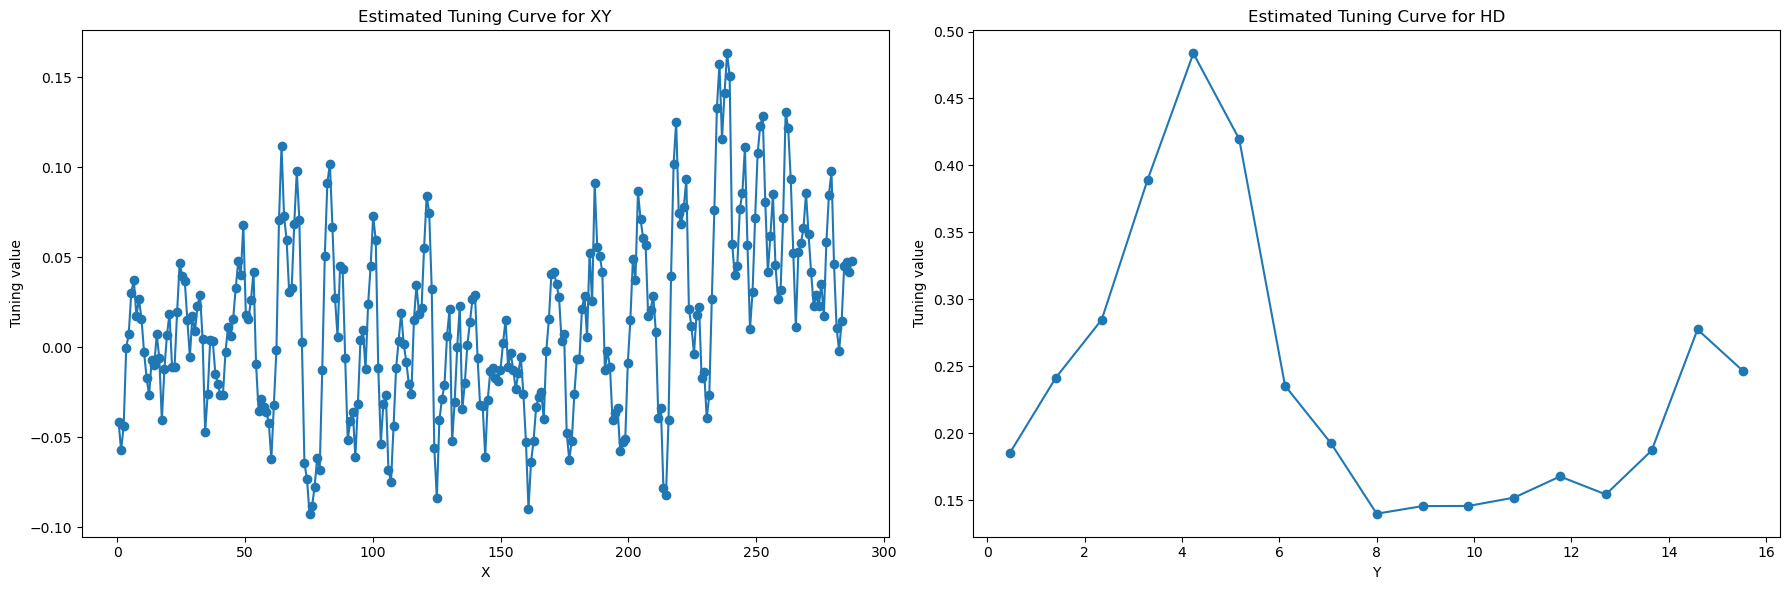

In [193]:
# display one neuron

# 2088
# 2148
# 2159
# 2167
# 4257
# 6332
# 6379
# 3108
# 2102
# 1133

neuron_idx += 1
fitted_params = per_n_fitted_params[neuron_idx]

a_edges = np.linspace(np.min(a_samples), np.max(a_samples), nbins_a + 1)
a_centers = (a_edges[:-1] + a_edges[1:]) / 2

# Compute bin edges and centers for dimension B
b_edges = np.linspace(np.min(b_samples), np.max(b_samples), nbins_b + 1)
b_centers = (b_edges[:-1] + b_edges[1:]) / 2

# Compute bin edges and centers for dimension C
#c_edges = np.linspace(np.min(c_samples), np.max(c_samples), nbins_c + 1)
#c_centers = (c_edges[:-1] + c_edges[1:]) / 2

# Split the fitted parameters into the three tuning curves
tuning_a_est = fitted_params[:nbins_a]
tuning_b_est = fitted_params[nbins_a:nbins_a+nbins_b]
#tuning_c_est = fitted_params[nbins_a+nbins_b:]

# Plot the tuning curves for dimensions A, B, and C
fig, axs = plt.subplots(1, 2, figsize=(18, 6))

# Dimension A
axs[0].plot(a_centers, tuning_a_est, marker='o', linestyle='-')
axs[0].set_title('Estimated Tuning Curve for XY')
axs[0].set_xlabel('X')
axs[0].set_ylabel('Tuning value')
#axs[0].set_ylim(0, 5)

# Dimension B
axs[1].plot(b_centers, tuning_b_est, marker='o', linestyle='-')
axs[1].set_title('Estimated Tuning Curve for HD')
axs[1].set_xlabel('Y')
axs[1].set_ylabel('Tuning value')
#axs[1].set_ylim(0, 5)

# Dimension C
#axs[2].plot(c_centers, tuning_c_est, marker='o', linestyle='-')
#axs[2].set_title('Estimated Tuning Curve for HD')
#axs[2].set_xlabel('Rotation')
#axs[2].set_ylabel('Tuning value')
#axs[2].set_ylim(0, 5)

plt.tight_layout()
#plt.savefig(f'glm-{neuron_idx}.svg')
plt.show()

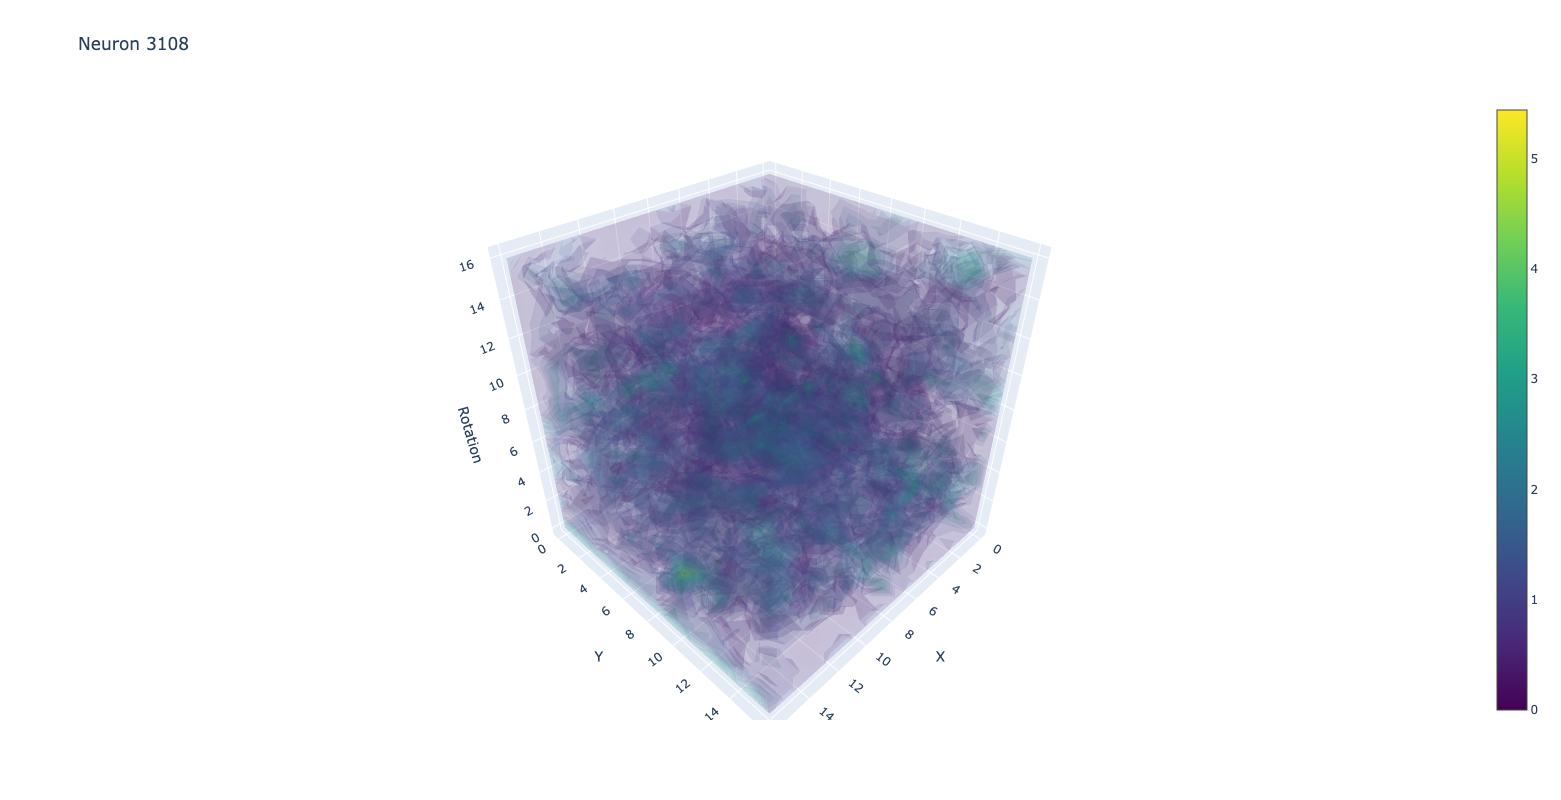

In [41]:
import numpy as np
import plotly.graph_objects as go

reps = model_reps[:, :, :, neuron].flatten()

fig = go.Figure(data=go.Volume(
    x=xx_flat,
    y=yy_flat,
    z=hhd_flat,
    value=reps,
    opacity=0.1,  # Adjust opacity to see through the volume
    isomin=np.min(reps),   # Minimum data value to visualize
    isomax=np.max(reps),   # Maximum data value to visualize
    surface_count=10,  # Number of isosurfaces
    colorscale='Viridis'
))

# Update layout for better visualization
fig.update_layout(
    title=f"Neuron {neuron_idx}",
    scene=dict(
        xaxis_title='X',
        yaxis_title='Y',
        zaxis_title='Rotation',
        xaxis=dict(nticks=10),
        yaxis=dict(nticks=10),
        zaxis=dict(nticks=10),
    ),
    width=800,
    height=800
)

# Display the interactive plot
fig.show()


In [ ]:
# 190, 250
# 400 is sparse

## Full simulation

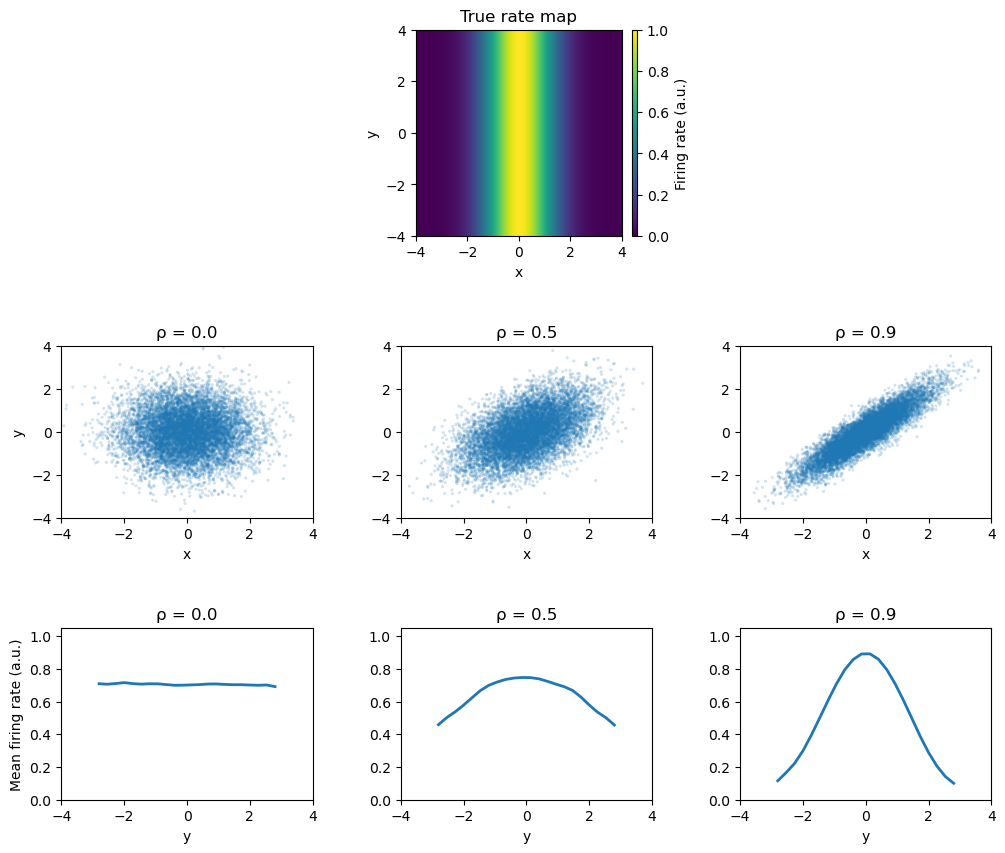

In [119]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import gridspec
from mpl_toolkits.axes_grid1 import make_axes_locatable   # tidy colour-bar

# ------------------------------------------------------------------
# 1.  Config
# ------------------------------------------------------------------
np.random.seed(42)
SIGMA_X     = 1.0                       # width of the Gaussian tuning
PEAK_RATE   = 1.0                       # <- stays in arbitrary units
N_SAMPLES   = 10_000
CORR_LEVELS = [0.0, 0.5, 0.9]
Y_BINS      = 30
GRID_LIM    = 4.0
# ------------------------------------------------------------------


# ------------------------------------------------------------------
# 2.  “True” firing-rate function – peaks at 1 a.u.
# ------------------------------------------------------------------
def firing_rate(x, y):
    return PEAK_RATE * np.exp(-0.5 * (x / SIGMA_X) ** 2)


# ------------------------------------------------------------------
# 3.  Figure layout
# ------------------------------------------------------------------
fig = plt.figure(figsize=(12, 10))
gs = gridspec.GridSpec(
    nrows=3,
    ncols=3,
    height_ratios=[1.2, 1.0, 1.0],
    hspace=0.4,
    wspace=0.35,
)

gs.update(hspace=0.60)  

ROW_TITLES = ["", "Sampling schemes", "Apparent tuning curves"]  # row labels


# ------------------------------------------------------------------
# 4.  Row 1 – true rate map (square, centred)
# ------------------------------------------------------------------
ax_rate = fig.add_subplot(gs[0, :])
ax_rate.set_box_aspect(1)                   # make the axes square

# compute and plot the rate map
grid = np.linspace(-GRID_LIM, GRID_LIM, 200)
rate_map = firing_rate(*np.meshgrid(grid, grid))
im = ax_rate.imshow(
    rate_map,
    extent=[-GRID_LIM, GRID_LIM, -GRID_LIM, GRID_LIM],
    origin="lower",
    cmap="viridis",
    aspect="equal",
    vmin=0, vmax=PEAK_RATE,
)

# stand-alone colour-bar so it can’t resize ax_rate
divider = make_axes_locatable(ax_rate)
cax = divider.append_axes("right", size="2.5%", pad=0.1)
cbar = fig.colorbar(im, cax=cax)
cbar.set_label("Firing rate (a.u.)")

ax_rate.set_xlabel("x")
ax_rate.set_ylabel("y")
ax_rate.set_anchor('C')                    # centre after colour-bar
ax_rate.set_title("True rate map")


# ------------------------------------------------------------------
# 5.  Rows 2 & 3 – loop over sampling schemes
# ------------------------------------------------------------------
for idx, rho in enumerate(CORR_LEVELS):
    # draw samples
    cov        = [[1.0, rho], [rho, 1.0]]
    sx, sy     = np.random.multivariate_normal([0, 0], cov, size=N_SAMPLES).T
    fr         = firing_rate(sx, sy)

    # ---------- Row 2: sampling scatter ---------------------------
    ax_samp = fig.add_subplot(gs[1, idx])
    ax_samp.scatter(sx, sy, s=5, alpha=0.2, edgecolor="none")
    ax_samp.set_xlim(-GRID_LIM, GRID_LIM)
    ax_samp.set_ylim(-GRID_LIM, GRID_LIM)
    ax_samp.set_xlabel("x")
    if idx == 0:
        ax_samp.set_ylabel("y")
    ax_samp.set_title(f"ρ = {rho:.1f}")

    # ---------- Row 3: marginal tuning (smoothed, correct) ----------
    bin_edges = np.linspace(-GRID_LIM, GRID_LIM, Y_BINS + 1)
    y_idx     = np.digitize(sy, bin_edges) - 1
    y_idx     = np.clip(y_idx, 0, Y_BINS - 1)
    
    # (1) accumulate *sums* and counts
    rate_sums = np.zeros(Y_BINS, dtype=float)   # total spikes per bin
    counts    = np.zeros(Y_BINS, dtype=int)     # samples per bin
    np.add.at(rate_sums, y_idx, fr)
    np.add.at(counts,   y_idx, 1)
    
    # (2) Gaussian-smooth numerator *and* denominator
    from scipy.ndimage import gaussian_filter1d
    sigma = 1          # width in bins – tweak to taste
    
    sm_sum    = gaussian_filter1d(rate_sums, sigma=sigma, mode="nearest")
    sm_counts = gaussian_filter1d(counts.astype(float), sigma=sigma, mode="nearest")
    
    # (3) divide once to get smoothed mean rate
    with np.errstate(divide="ignore", invalid="ignore"):
        sm_rates = np.divide(sm_sum, sm_counts, where=sm_counts > 0)
    
    # (4) blank bins still too under-sampled after smoothing
    MIN_COUNT = 20
    sm_rates[sm_counts < MIN_COUNT] = np.nan
    
    # (5) plot
    bin_centres = 0.5 * (bin_edges[:-1] + bin_edges[1:])
    ax_marg = fig.add_subplot(gs[2, idx])
    ax_marg.plot(bin_centres, sm_rates, lw=2)
    ax_marg.set_xlim(-GRID_LIM, GRID_LIM)
    ax_marg.set_ylim(0, PEAK_RATE * 1.05)
    ax_marg.set_xlabel("y")
    if idx == 0:
        ax_marg.set_ylabel("Mean firing rate (a.u.)")
    ax_marg.set_title(f"ρ = {rho:.1f}")

plt.savefig('/home/mag/variance-analysis/figs/fig1a.png', dpi=300)